# EDA inicial — Lending Club accepted loans

Estudo exploratório do dataset de empréstimos aceitos (2007–2018Q4) para o baseline de credit scoring.

Objetivos:

- Conferir volume, alvo e cobertura temporal antes de treinar o modelo.
- Separar variáveis disponíveis na concessão de variáveis que vazam o desfecho.
- Excluir identificadores e texto livre da análise, em linha com a LGPD.
- Orientar o corte entre dataset de referência e dataset de produção.

Fonte: [wordsforthewise/lending-club](https://www.kaggle.com/datasets/wordsforthewise/lending-club), licença CC0.
Arquivo local, fora do Git: `data/raw/accepted_2007_to_2018Q4.csv.gz`.


## 1. Ambiente e escopo

A leitura percorre o arquivo compactado em blocos. O perfil de status e de ano usa a população inteira. Gráficos de distribuição usam uma amostra reproduzível de 4% dos empréstimos com desfecho fechado.

Não entram nesta análise:

- Identificadores e quase identificadores: `id`, `member_id`, `url`, `emp_title`, `zip_code`, `desc`, `title`.
- Variáveis posteriores à concessão: pagamentos, recuperações, FICO atual, hardship e settlement. Usá-las no modelo vazaria o alvo.


In [1]:
from __future__ import annotations

from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA_PATH = ROOT / "data" / "raw" / "accepted_2007_to_2018Q4.csv.gz"
SAMPLE_FRACTION = 0.04
RANDOM_STATE = 42
CLOSED_STATUSES = ("Fully Paid", "Charged Off")

APPLICATION_COLUMNS = [
    "loan_amnt",
    "term",
    "int_rate",
    "installment",
    "grade",
    "sub_grade",
    "emp_length",
    "home_ownership",
    "annual_inc",
    "verification_status",
    "issue_d",
    "loan_status",
    "purpose",
    "addr_state",
    "dti",
    "delinq_2yrs",
    "fico_range_low",
    "fico_range_high",
    "inq_last_6mths",
    "open_acc",
    "pub_rec",
    "revol_bal",
    "revol_util",
    "total_acc",
    "application_type",
    "pub_rec_bankruptcies",
]

sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 40)
pd.set_option("display.float_format", lambda value: f"{value:,.2f}")

print(f"pandas {pd.__version__}")
print(DATA_PATH)
print(f"arquivo encontrado: {DATA_PATH.exists()}")


pandas 3.0.6
c:\Users\efralmeida\OneDrive - Sefaz-SP\Documentos\Eduardo\Pessoal\Cursos\FIAP ML\Tech Challenge 04\tc4-credit-scoring\data\raw\accepted_2007_to_2018Q4.csv.gz
arquivo encontrado: True


## 2. Perfil da população e amostra

`Charged Off` é o evento de inadimplência. `Fully Paid` é o não evento. Status em aberto (`Current`, `Late`, `In Grace Period`) ficam de fora do alvo porque o desfecho ainda não ocorreu.

Status antigos no formato `Does not meet the credit policy. Status:...` são normalizados para o desfecho correspondente.


In [2]:
def normalize_status(status: str) -> str:
    """Reduz o status bruto ao desfecho de crédito, quando ele existe.

    Args:
        status: Valor original de `loan_status`.

    Returns:
        `Fully Paid`, `Charged Off` ou o status original.
    """
    text = str(status)
    if "Fully Paid" in text:
        return "Fully Paid"
    if "Charged Off" in text:
        return "Charged Off"
    return text


def profile_and_sample(path: Path, fraction: float, seed: int) -> tuple[pd.DataFrame, pd.Series, pd.Series]:
    """Percorre o arquivo uma vez e devolve contagens populacionais e a amostra.

    Args:
        path: Caminho do CSV compactado.
        fraction: Fração de empréstimos fechados retirada de cada bloco.
        seed: Semente da amostragem.

    Returns:
        Amostra de empréstimos fechados, contagem de status e contagem por ano.
    """
    status_counts: Counter[str] = Counter()
    year_counts: Counter[int] = Counter()
    parts: list[pd.DataFrame] = []

    reader = pd.read_csv(
        path,
        usecols=APPLICATION_COLUMNS,
        chunksize=250_000,
        low_memory=False,
    )
    for chunk in reader:
        status_counts.update(chunk["loan_status"].astype(str).value_counts().to_dict())
        issued = pd.to_datetime(chunk["issue_d"], format="%b-%Y", errors="coerce")
        year_counts.update(issued.dt.year.dropna().astype(int).value_counts().to_dict())

        chunk = chunk.copy()
        chunk["loan_status"] = chunk["loan_status"].map(normalize_status)
        closed = chunk[chunk["loan_status"].isin(CLOSED_STATUSES)]
        if not closed.empty:
            parts.append(closed.sample(frac=fraction, random_state=seed))

    sample = pd.concat(parts, ignore_index=True)
    return sample, pd.Series(status_counts).sort_values(ascending=False), pd.Series(year_counts).sort_index()


sample, status_counts, year_counts = profile_and_sample(DATA_PATH, SAMPLE_FRACTION, RANDOM_STATE)

print(f"registros no arquivo: {int(status_counts.sum()):,}")
print(f"amostra fechada: {len(sample):,}")
status_counts.to_frame("registros")


registros no arquivo: 2,260,668
amostra fechada: 53,922


,registros
Fully Paid,1076751
Current,878317
Charged Off,268559
Late (31-120 days),21467
In Grace Period,8436
Late (16-30 days),4349
Does not meet the credit policy. Status:Fully Paid,1988
Does not meet the credit policy. Status:Charged Off,761
Default,40


In [3]:
population = pd.DataFrame({"ano": year_counts.index.astype(int), "registros": year_counts.values})
closed_rate = sample["loan_status"].value_counts(normalize=True).rename("proporcao")
target_counts = sample["loan_status"].value_counts().rename("amostra")
pd.concat([target_counts, closed_rate], axis=1)


,amostra,proporcao
loan_status,,
Fully Paid,43162,0.80
Charged Off,10760,0.20


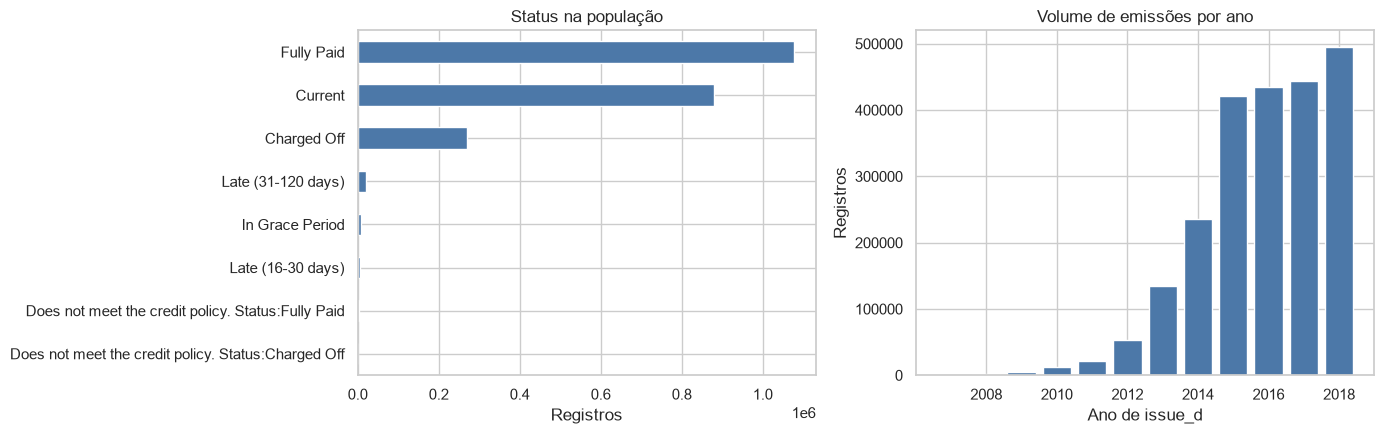

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

status_counts.head(8).sort_values().plot.barh(ax=axes[0], color="#4C78A8")
axes[0].set_title("Status na população")
axes[0].set_xlabel("Registros")

axes[1].bar(population["ano"], population["registros"], color="#4C78A8")
axes[1].set_title("Volume de emissões por ano")
axes[1].set_xlabel("Ano de issue_d")
axes[1].set_ylabel("Registros")

fig.tight_layout()


## 3. Preparação da amostra

O alvo do baseline será binário: `default = 1` quando o status normalizado é `Charged Off`.

`issue_d` permite, na etapa seguinte, separar referência e produção por tempo. Um corte natural aparece depois de 2015, quando o volume muda de patamar. A decisão final do corte fica para o pipeline, não para este notebook.


In [5]:
def prepare_sample(frame: pd.DataFrame) -> pd.DataFrame:
    """Tipa datas e cria o alvo binário da amostra fechada.

    Args:
        frame: Amostra com status já normalizado.

    Returns:
        Cópia com `issue_d` em data e `default` inteiro.
    """
    prepared = frame.copy()
    prepared["issue_d"] = pd.to_datetime(prepared["issue_d"], format="%b-%Y", errors="coerce")
    prepared["issue_year"] = prepared["issue_d"].dt.year
    prepared["default"] = (prepared["loan_status"] == "Charged Off").astype(int)
    prepared["term"] = prepared["term"].astype(str).str.strip()
    return prepared


loans = prepare_sample(sample)
print(f"taxa de default na amostra: {loans['default'].mean():.2%}")
print(f"período: {loans['issue_d'].min():%Y-%m} a {loans['issue_d'].max():%Y-%m}")
loans.head(3)


taxa de default na amostra: 19.95%
período: 2007-06 a 2018-12


,loan_amnt,term,int_rate,installment,grade,sub_grade,emp_length,home_ownership,annual_inc,verification_status,issue_d,loan_status,purpose,addr_state,dti,delinq_2yrs,fico_range_low,fico_range_high,inq_last_6mths,open_acc,pub_rec,revol_bal,revol_util,total_acc,application_type,pub_rec_bankruptcies,issue_year,default
0,"14,000.00",60 months,17.57,352.25,D,D4,< 1 year,RENT,"40,000.00",Source Verified,2015-10-01,Fully Paid,debt_consolidation,CO,19.44,0.00,695.00,699.00,1.00,6.00,1.00,"13,513.00",50.00,13.00,Individual,1.00,2015,0
1,"13,000.00",36 months,10.99,425.55,B,B4,1 year,RENT,"45,000.00",Source Verified,2015-10-01,Fully Paid,debt_consolidation,FL,18.74,0.00,665.00,669.00,0.00,12.00,0.00,"18,069.00",73.50,19.00,Individual,0.00,2015,0
2,"15,000.00",36 months,13.33,507.80,C,C3,2 years,MORTGAGE,"35,000.00",Verified,2015-07-01,Fully Paid,debt_consolidation,CA,34.69,0.00,670.00,674.00,0.00,11.00,0.00,"18,130.00",62.30,18.00,Individual,0.00,2015,0


## 4. Qualidade dos campos de concessão

Estas ausências orientam as regras do data contract. Para a etapa 1, candidatas a regras rígidas:

- `loan_amnt`, `int_rate`, `annual_inc`, `dti` e `fico_range_low` não podem ser nulos.
- `annual_inc` deve ser positivo e `dti` não pode ser negativo.
- `loan_status` precisa pertencer ao domínio conhecido.
- `term` precisa ser `36 months` ou `60 months`.


In [6]:
missing = (
    loans.isna()
    .mean()
    .mul(100)
    .rename("ausentes_pct")
    .sort_values(ascending=False)
    .to_frame()
)
missing["ausentes"] = loans.isna().sum()
missing.head(12)


,ausentes_pct,ausentes
emp_length,5.58,3007
pub_rec_bankruptcies,0.11,58
revol_util,0.07,38
dti,0.02,10
open_acc,0.01,3
inq_last_6mths,0.01,3
total_acc,0.01,3
pub_rec,0.01,3
delinq_2yrs,0.01,3
loan_amnt,0.00,0


In [7]:
numeric_summary = loans[
    ["loan_amnt", "int_rate", "installment", "annual_inc", "dti", "fico_range_low", "revol_util"]
].describe(percentiles=[0.01, 0.05, 0.5, 0.95, 0.99]).T
numeric_summary


,count,mean,std,min,1%,5%,50%,95%,99%,max
loan_amnt,"53,922.00","14,403.11","8,693.80",500.00,"1,500.00","3,125.00","12,000.00","32,000.00","35,000.00","40,000.00"
int_rate,"53,922.00",13.25,4.76,5.31,5.32,6.49,12.74,22.15,26.30,30.99
installment,"53,922.00",437.25,260.60,16.85,51.23,107.61,375.43,958.40,"1,217.12","1,569.11"
annual_inc,"53,922.00","75,926.53","65,827.74",0.00,"18,000.00","28,000.00","65,000.00","155,000.00","255,000.00","6,000,000.00"
dti,"53,912.00",18.26,10.79,0.00,1.84,5.03,17.56,32.99,38.38,999.00
fico_range_low,"53,922.00",696.15,31.85,640.00,660.00,660.00,690.00,760.00,800.00,845.00
revol_util,"53,884.00",51.81,24.50,0.00,1.10,10.30,52.10,91.40,98.30,125.20


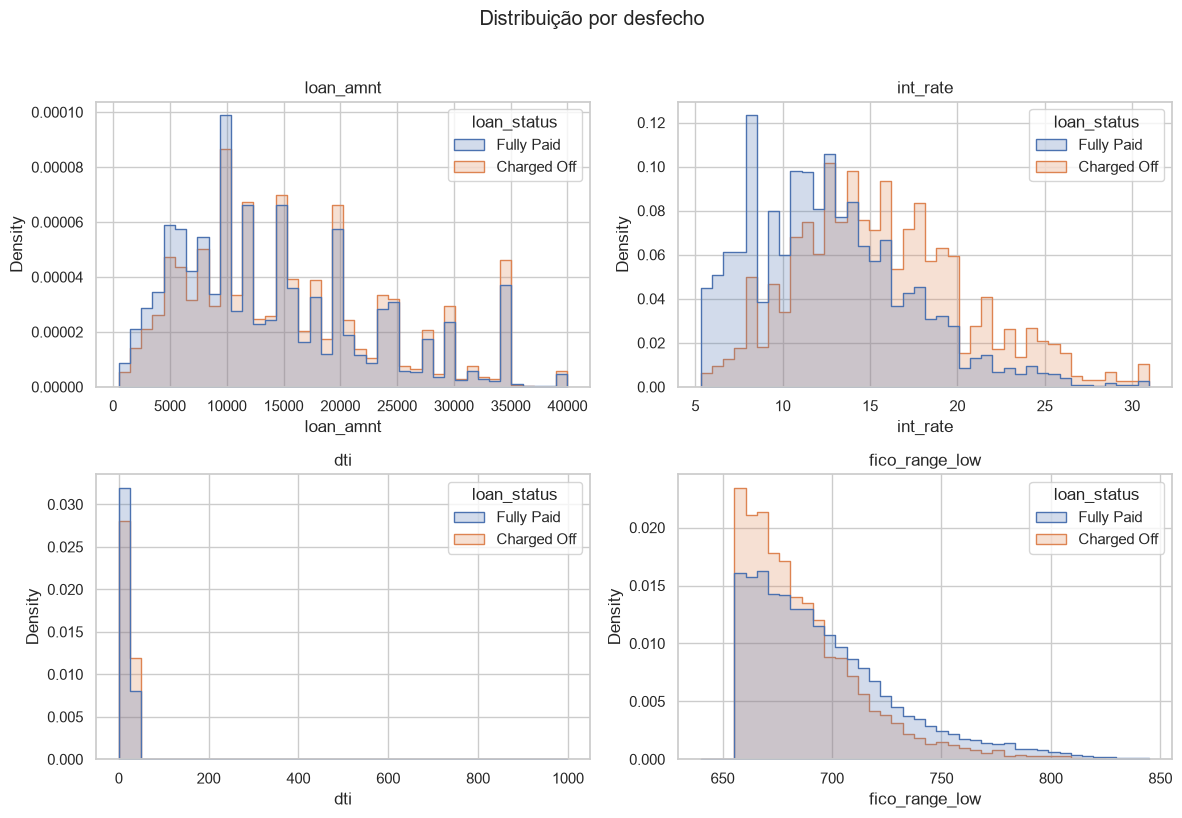

In [8]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
plot_columns = ["loan_amnt", "int_rate", "dti", "fico_range_low"]
for axis, column in zip(axes.ravel(), plot_columns):
    sns.histplot(
        data=loans,
        x=column,
        hue="loan_status",
        bins=40,
        element="step",
        stat="density",
        common_norm=False,
        ax=axis,
    )
    axis.set_title(column)

fig.suptitle("Distribuição por desfecho", y=1.02)
fig.tight_layout()


## 5. Categorias e risco observado

Grade, prazo e finalidade são as primeiras variáveis categóricas do contrato. A taxa abaixo é descritiva: não está ajustada por mix de crédito nem por ano.


In [9]:
def default_rate_by(frame: pd.DataFrame, column: str, min_count: int = 50) -> pd.DataFrame:
    """Calcula volume e taxa de default por categoria.

    Args:
        frame: Amostra com a coluna `default`.
        column: Categoria a agregar.
        min_count: Frequência mínima para manter a categoria.

    Returns:
        Tabela ordenada pela taxa de default.
    """
    grouped = (
        frame.groupby(column, dropna=False)
        .agg(emprestimos=("default", "size"), defaults=("default", "sum"), taxa_default=("default", "mean"))
        .reset_index()
    )
    return grouped[grouped["emprestimos"] >= min_count].sort_values("taxa_default", ascending=False)


grade_risk = default_rate_by(loans, "grade", min_count=1).sort_values("grade")
purpose_risk = default_rate_by(loans, "purpose")
term_risk = default_rate_by(loans, "term", min_count=1)
grade_risk


,grade,emprestimos,defaults,taxa_default
0,A,9407,575,0.06
1,B,15543,2151,0.14
2,C,15434,3393,0.22
3,D,8108,2455,0.30
4,E,3753,1429,0.38
5,F,1343,592,0.44
6,G,334,165,0.49


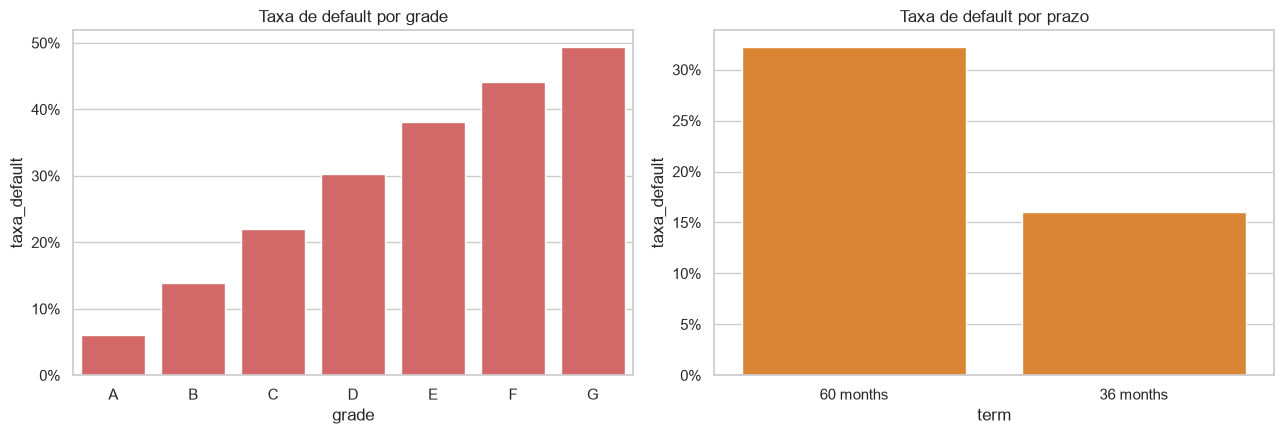

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

sns.barplot(data=grade_risk, x="grade", y="taxa_default", color="#E45756", ax=axes[0])
axes[0].set_title("Taxa de default por grade")
axes[0].yaxis.set_major_formatter(plt.FuncFormatter(lambda value, _: f"{value:.0%}"))

sns.barplot(data=term_risk, x="term", y="taxa_default", color="#F58518", ax=axes[1])
axes[1].set_title("Taxa de default por prazo")
axes[1].yaxis.set_major_formatter(plt.FuncFormatter(lambda value, _: f"{value:.0%}"))

fig.tight_layout()


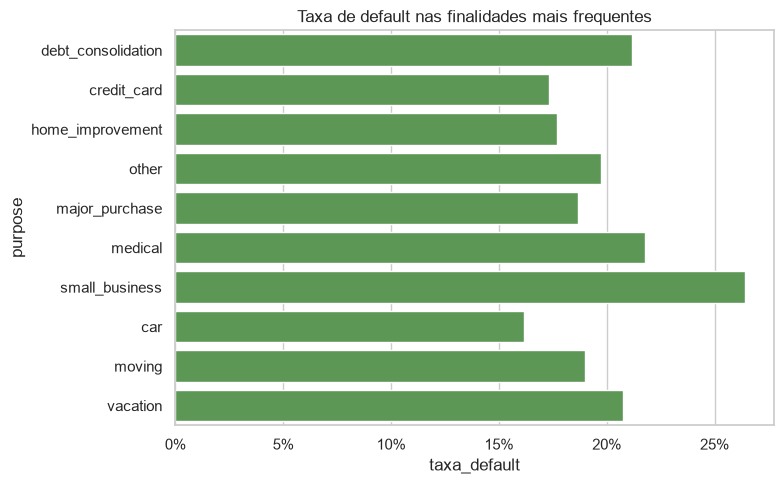

In [11]:
top_purposes = purpose_risk.sort_values("emprestimos", ascending=False).head(10)
fig, axis = plt.subplots(figsize=(8, 5))
sns.barplot(data=top_purposes, y="purpose", x="taxa_default", color="#54A24B", ax=axis)
axis.set_title("Taxa de default nas finalidades mais frequentes")
axis.xaxis.set_major_formatter(plt.FuncFormatter(lambda value, _: f"{value:.0%}"))
fig.tight_layout()


## 6. Tempo e associação entre variáveis

A série anual mostra se a taxa de default muda com o ciclo. Isso ainda não é concept drift: o mix de grade, prazo e renda também pode ter mudado. A comparação formal fica para o relatório do Evidently.

O mapa de correlação usa apenas variáveis numéricas de concessão. `installment` tende a acompanhar `loan_amnt`; as duas não devem entrar juntas sem critério.


,issue_year,emprestimos,defaults,taxa_default
1,2008,105,16,0.15
2,2009,220,35,0.16
3,2010,538,65,0.12
4,2011,835,124,0.15
5,2012,2159,358,0.17
6,2013,5361,833,0.16
7,2014,8971,1645,0.18
8,2015,15030,2988,0.20
9,2016,11579,2749,0.24
10,2017,6823,1582,0.23


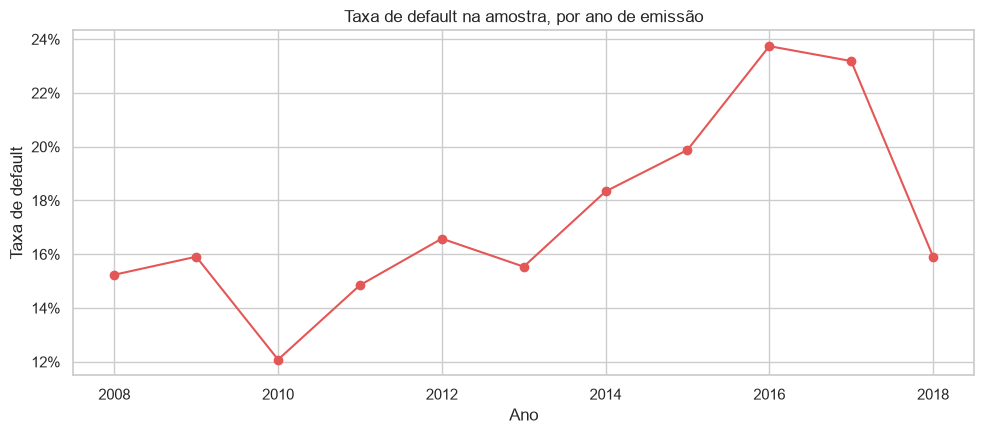

In [12]:
yearly = default_rate_by(loans.dropna(subset=["issue_year"]), "issue_year", min_count=30)
yearly["issue_year"] = yearly["issue_year"].astype(int)
yearly = yearly.sort_values("issue_year")

fig, axis = plt.subplots(figsize=(10, 4.5))
axis.plot(yearly["issue_year"], yearly["taxa_default"], marker="o", color="#E45756")
axis.set_title("Taxa de default na amostra, por ano de emissão")
axis.set_xlabel("Ano")
axis.set_ylabel("Taxa de default")
axis.yaxis.set_major_formatter(plt.FuncFormatter(lambda value, _: f"{value:.0%}"))
fig.tight_layout()
yearly


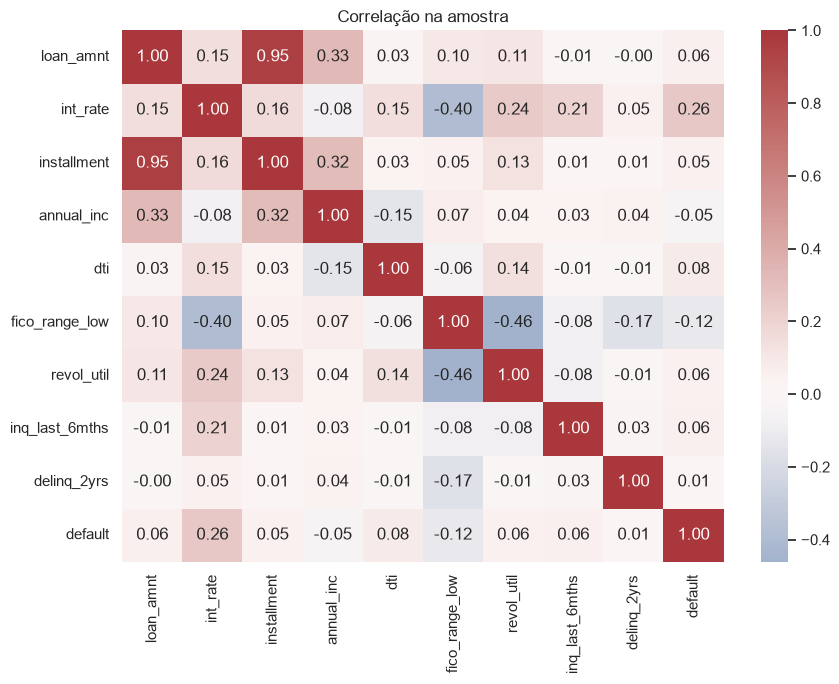

In [13]:
correlation_columns = [
    "loan_amnt",
    "int_rate",
    "installment",
    "annual_inc",
    "dti",
    "fico_range_low",
    "revol_util",
    "inq_last_6mths",
    "delinq_2yrs",
    "default",
]
correlation = loans[correlation_columns].corr(numeric_only=True)

fig, axis = plt.subplots(figsize=(9, 7))
sns.heatmap(correlation, cmap="vlag", center=0, annot=True, fmt=".2f", ax=axis)
axis.set_title("Correlação na amostra")
fig.tight_layout()


## 7. Leitura para as próximas etapas

- O alvo supervisionado deve usar somente empréstimos `Fully Paid` e `Charged Off`.
- O contrato inicial pode exigir não nulos e domínios fechados em valor, taxa, renda, DTI, FICO, prazo e status.
- `grade` e `int_rate` separam risco já na análise descritiva. São candidatas à simulação de drift, junto com `annual_inc` e `dti`.
- `addr_state` fica restrito a monitoramento de mix. Não deve virar feature de decisão sem avaliação de viés.
- Referência e produção devem ser cortadas por `issue_d`, não por amostra aleatória.
- Identificadores, ZIP, URL, cargo e texto livre não devem ser persistidos no pipeline de treino nem nos logs de predição.

Este notebook não treina o modelo e não mede drift. Ele só fixa o recorte, o alvo e as variáveis que podem entrar na concessão.
